### Data Preprocessing

This notebook prepares the dataset for binary classification, including duplicate removal, target definition and train-test splitting.

#### Data Loading

In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

data_path = Path("../data/raw/winequality-red.csv")
df = pd.read_csv(data_path, sep=",")

print(f"Original dataset shape: {df.shape}")

Original dataset shape: (1599, 12)


#### Duplicate Removal

Remove duplicate observations to avoid redundant records in the dataset.

In [25]:
initial_rows = len(df)

df = df.drop_duplicates().copy()

removed_rows = initial_rows - len(df)

print(f"Removed duplicates: {removed_rows}")
print(f"Dataset shape after removal: {df.shape}")

Removed duplicates: 240
Dataset shape after removal: (1359, 12)


A total of 240 duplicate rows were removed, reducing the dataset to 1,359 unique observations.

#### Target Definition

Convert the original quality scores into a binary target, using 7 as the classification threshold.

In [26]:
df["quality_class"] = (df["quality"] >= 7).astype(int)

df[["quality", "quality_class"]].head(10)

,quality,quality_class
0,5,0
1,5,0
2,5,0
3,6,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0
10,5,0


#### Class Distribution

In [27]:
class_counts = df["quality_class"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / len(df) * 100).round(2)
})

class_distribution.index = ["Below 7", "High quality"]

display(class_distribution)

,Count,Percentage
Below 7,1175,86.46
High quality,184,13.54


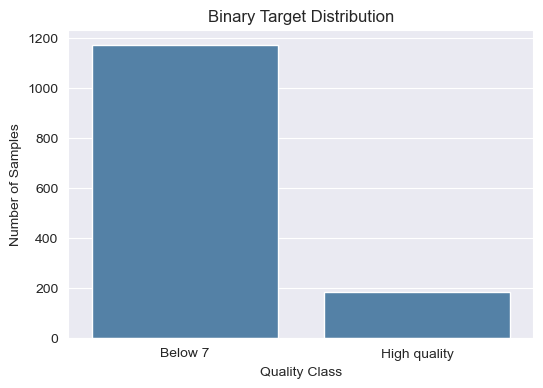

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="quality_class", color="steelblue")

plt.title("Binary Target Distribution")
plt.xlabel("Quality Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Below 7", "High quality"])

plt.show()

The binary target presents an imbalanced class distribution, with fewer high-quality samples. This imbalance will be considered during model training.

#### Feature and Target Separation

Separate the predictors from the binary target. The original quality score is excluded to prevent target leakage.

In [29]:
X = df.drop(columns=["quality", "quality_class"])
y = df["quality_class"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (1359, 11)
Target shape: (1359,)


#### Train-Test Split

Split the dataset into training (80%) and testing (20%) sets

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

Training set: (1087, 11)
Testing set: (272, 11)


In [31]:
split_distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).sort_index() * 100

split_distribution.index = ["Below 7", "High quality"]

display(split_distribution.round(2))

,Training,Testing
Below 7,86.48,86.4
High quality,13.52,13.6


Stratified sampling preserves similar class proportions in both subsets, providing a representative basis for model training and evaluation.

In [32]:
processed_dir = data_path.parents[1] / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(processed_dir / "cleaned_dataset.csv", index=False)

train_data = X_train.copy()
train_data["quality_class"] = y_train

test_data = X_test.copy()
test_data["quality_class"] = y_test

train_data.to_csv(processed_dir / "train.csv", index=False)
test_data.to_csv(processed_dir / "test.csv", index=False)